In [7]:
import import_ipynb
import data_analysis
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import HuberRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [8]:
reg_features = ['Income_Category', 'Card_Category_Blue', 'Total_Trans_Amt',
                 'Card_Category_Silver', 'Total_Trans_Ct', 'Card_Category_Gold',
                 'Dependent_count']

Xr_train = data_analysis.Xr_train[reg_features]
Xr_test = data_analysis.Xr_test[reg_features]
yr_train = data_analysis.yr_train
yr_test = data_analysis.yr_test

continuous_cols = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Dependent_count']
scaler = StandardScaler()
Xr_train_scaled = Xr_train.copy()
Xr_test_scaled = Xr_test.copy()
Xr_train_scaled[continuous_cols] = scaler.fit_transform(Xr_train[continuous_cols])
Xr_test_scaled[continuous_cols] = scaler.transform(Xr_test[continuous_cols])

In [9]:
class HuberRegressionScratch:
    def __init__(self, delta=1500.0, max_iter=50, tol=1e-6, init="ols"):
        self.delta = delta
        self.max_iter = max_iter
        self.tol = tol
        self.init = init
        self.coef_ = None
        self.intercept_ = None
        self.loss_history = []

    def _huber_loss(self, residual):
        abs_r = np.abs(residual)
        quad = 0.5 * residual ** 2
        lin = self.delta * (abs_r - 0.5 * self.delta)
        return np.mean(np.where(abs_r <= self.delta, quad, lin))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        m, n = X.shape
        X_b = np.c_[np.ones((m, 1)), X]
        y = np.asarray(y, dtype=float).ravel()
        self.loss_history = []

        if self.init == "zeros":
            theta = np.zeros(n + 1)
        else:
            theta = np.linalg.lstsq(X_b, y, rcond=None)[0]  

        for i in range(self.max_iter):
            residual = X_b @ theta - y
            abs_r = np.abs(residual)
            weights = np.where(abs_r <= self.delta, 1.0, self.delta / (abs_r + 1e-8))

            WX = X_b * weights[:, None]
            theta_new = np.linalg.solve(X_b.T @ WX, WX.T @ y)

            self.loss_history.append(self._huber_loss(residual))

            if np.linalg.norm(theta_new - theta) < self.tol:
                theta = theta_new
                break
            theta = theta_new

        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

In [10]:
from sklearn.model_selection import KFold

def cv_delta_search(X, y, deltas, n_splits=5, seed=42):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    out = []
    for delta in deltas:
        r2s, maes = [], []
        for tr, va in kf.split(X):
            m = HuberRegressionScratch(delta=delta, max_iter=100).fit(X[tr], y[tr])
            p = m.predict(X[va])
            r2s.append(r2_score(y[va], p))
            maes.append(mean_absolute_error(y[va], p))
        out.append((delta, float(np.mean(r2s)), float(np.mean(maes))))
    return out

results = cv_delta_search(Xr_train_scaled.values, yr_train,
                          [1500, 3000, 4500, 6000, 9000, 15000, 1e12])   # 1e12 เท่ากับ OLS
for delta, cv_r2, cv_mae in results:
    print(f"delta={delta:<10g} CV R² = {cv_r2:.4f}   CV MAE = {cv_mae:.1f}")

best_delta = max(results, key=lambda r: r[1])[0]
print("\nbest delta by CV R²:", best_delta)

huber_model = HuberRegressionScratch(delta=best_delta, max_iter=50, init="zeros")
huber_model.fit(Xr_train_scaled.values, yr_train)
y_pred_huber = huber_model.predict(Xr_test_scaled.values)

print("R² =", r2_score(yr_test, y_pred_huber))
print("MSE =", mean_squared_error(yr_test, y_pred_huber))
print("MAE =", mean_absolute_error(yr_test, y_pred_huber))

delta=1500       CV R² = 0.5097   CV MAE = 4226.5
delta=3000       CV R² = 0.5160   CV MAE = 4228.9
delta=4500       CV R² = 0.5249   CV MAE = 4237.3
delta=6000       CV R² = 0.5312   CV MAE = 4249.2
delta=9000       CV R² = 0.5381   CV MAE = 4270.9
delta=15000      CV R² = 0.5434   CV MAE = 4313.9
delta=1e+12      CV R² = 0.5438   CV MAE = 4332.8

best delta by CV R²: 1000000000000.0
R² = 0.538508612655074
MSE = 38200742.00071501
MAE = 4252.173550182181


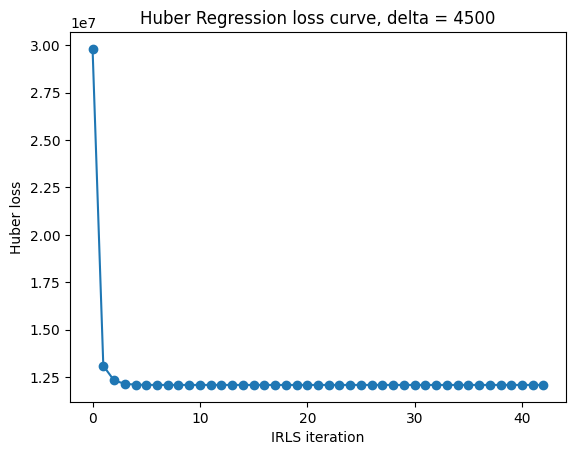

In [12]:
# loss curve
huber_curve = HuberRegressionScratch(delta=4500, max_iter=50, init="zeros")
huber_curve.fit(Xr_train_scaled.values, yr_train)

plt.plot(huber_curve.loss_history, marker='o')
plt.xlabel('IRLS iteration')
plt.ylabel('Huber loss')
plt.title('Huber Regression loss curve, delta = 4500')
plt.show()

In [13]:
sk_huber = HuberRegressor(epsilon=1.35, max_iter=2000)
sk_huber.fit(Xr_train_scaled.values, yr_train)
y_pred_sk_huber = sk_huber.predict(Xr_test_scaled.values)

print("sklearn R² =", r2_score(yr_test, y_pred_sk_huber))

sklearn R² = 0.5195408216410922
